# CS-781 Phase 1 — Low-Memory Data Exploration

This version is designed for Kaggle sessions where loading the four legal
training JSON files into Python memory causes the kernel to die.

### Key changes

- **Never use `json.load()` on the large training files.**
- Read each JSON array **one record at a time** using `ijson`.
- Do not keep the whole corpus in RAM.
- Use reservoir sampling for random document inspection.
- Compute document statistics in a streaming pass.
- Keep vocabulary/bigram exploration to a bounded sample.
- Use a small tokenizer sample rather than tokenizing the corpus.
- Do not build giant Python sets/counters containing the entire corpus.

The four Phase-1 sources are:
- Acts
- High Courts
- Supreme Court
- Tribunals

In [11]:
# ============================================================
# CELL 1 — Imports and reproducibility
# ============================================================

import os
import sys
import subprocess
import importlib.util
import random
import re
import hashlib
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Imports successful.")

Imports successful.


In [12]:
# ============================================================
# CELL 2 — Install/import ijson
# ============================================================

# ijson lets us parse a huge JSON array one record at a time.
# This prevents json.load() from putting the complete file in RAM.

if importlib.util.find_spec("ijson") is None:
    print("ijson not found. Installing...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ijson"
    ])

import ijson

print("ijson version:", getattr(ijson, "__version__", "installed"))

ijson version: 3.5.1


In [13]:
# ============================================================
# CELL 3 — Hugging Face authentication
# ============================================================

from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

# Kaggle Secret name from the starter notebook
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

login(token=HF_TOKEN)

print("Hugging Face login successful.")

Hugging Face login successful.


In [14]:
# ============================================================
# CELL 4 — Device
# ============================================================

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available.")

print("Note: data exploration itself is CPU/RAM work.")

Device: cuda
GPU: Tesla T4
Note: data exploration itself is CPU/RAM work.


In [15]:
# ============================================================
# CELL 5 — Configuration
# ============================================================

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

TRAIN_FILES = {
    "Acts": "Phase_1_Pretraining/Train/train_acts.json",
    "High Courts": "Phase_1_Pretraining/Train/train_high_courts.json",
    "Supreme Court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Tribunals": "Phase_1_Pretraining/Train/train_tribunals.json",
}

# Keep exploration bounded.
RANDOM_SAMPLE_SIZE = 5
TOKENIZATION_SAMPLE_SIZE = 50

# For vocabulary/bigram exploration, process at most this many
# non-empty documents from each source.
VOCAB_SAMPLE_DOCUMENTS = 5000

# Maximum characters used by the bounded vocabulary sample.
VOCAB_SAMPLE_CHARS = 20_000_000

print("Dataset:", HF_DATASET_REPO)

for source, filename in TRAIN_FILES.items():
    print(f"{source:20s} -> {filename}")

Dataset: Exploration-Lab/CS-781-Capstone
Acts                 -> Phase_1_Pretraining/Train/train_acts.json
High Courts          -> Phase_1_Pretraining/Train/train_high_courts.json
Supreme Court        -> Phase_1_Pretraining/Train/train_supreme_court.json
Tribunals            -> Phase_1_Pretraining/Train/train_tribunals.json


In [16]:
# ============================================================
# CELL 6 — Download ALL four Phase-1 training files
# ============================================================

from huggingface_hub import hf_hub_download

file_paths = {}

for source, filename in TRAIN_FILES.items():

    print(f"\nDownloading {source}...")
    print("File:", filename)

    file_paths[source] = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        token=HF_TOKEN
    )

    print("Local path:", file_paths[source])

print("\nAll four files are available.")


File: Phase_1_Pretraining/Train/train_acts.json


Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Local path: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json

File: Phase_1_Pretraining/Train/train_high_courts.json


Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Local path: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json

File: Phase_1_Pretraining/Train/train_supreme_court.json


Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Local path: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json

File: Phase_1_Pretraining/Train/train_tribunals.json


Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

Local path: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json

All four files are available.


In [17]:
# ============================================================
# CELL 7 — Verify file sizes WITHOUT loading them
# ============================================================

for source, path in file_paths.items():

    size_gb = os.path.getsize(path) / (1024 ** 3)
    size_mb = os.path.getsize(path) / (1024 ** 2)

    print(
        f"{source:20s} | "
        f"{size_gb:8.3f} GB | "
        f"{size_mb:10.1f} MB"
    )

Acts                 |    0.679 GB |      695.0 MB
High Courts          |    9.940 GB |    10178.1 MB
Supreme Court        |    1.232 GB |     1261.3 MB
Tribunals            |    6.039 GB |     6183.6 MB


In [18]:
# ============================================================
# CELL 8 — Streaming helper
# ============================================================

def stream_records(path):
    """Yield one JSON-array record at a time."""

    with open(path, "rb") as f:
        for record in ijson.items(f, "item"):
            yield record


def text_from_record(record):
    """Safely get text from a record."""

    text = record.get("text", "")

    if text is None:
        return ""

    return str(text)


print("Streaming helpers ready.")

Streaming helpers ready.


In [19]:
# ============================================================
# CELL 9 — Inspect ONE record without loading the dataset
# ============================================================

for source, path in file_paths.items():

    first_record = next(stream_records(path))

    print("=" * 80)
    print(source)
    print("=" * 80)

    print("Record type:", type(first_record))
    print("Keys:", list(first_record.keys()))

    print("\nFirst 3000 characters of text:")
    print(text_from_record(first_record)[:3000])

    # Only inspect one record from each source.

Acts
Record type: <class 'dict'>
Keys: ['title', 'category', 'year', 'url', 'text', 'word_count', 'text_length_chars']

First 3000 characters of text:
Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore City Planning Area Zonal Regulations 1972, which was in vogue till 1984, provided for construction of five floors including ground floor. The Corporation of the City of Bangalore granted permission for construction of buildings beyond five floors in certain cases. In respect of some of the buildings the permission granted by the Corporation contrary to the Zonal Regulations then in force was questioned in the High Court and the Division Bench of the High Court held that the permission granted in violation of the Zonal Regulation was illegal. The matter was taken to the Supreme Court. The Supreme Court dismissed it on 19-1-1987 with a direction that the judgeme

In [20]:
# ============================================================
# CELL 10 — Streaming quality + length statistics
# ============================================================

stats = {}

for source, path in file_paths.items():

    print(f"Processing {source}...")

    count = 0
    missing_text = 0
    none_text = 0
    empty_text = 0

    total_chars = 0
    total_words = 0

    min_words = None
    max_words = 0

    # Online statistics for word length.
    # Keep a bounded sample for percentile estimation.
    length_sample = []

    # Reservoir sample of actual documents for later inspection.
    reservoir = []

    for record in stream_records(path):

        count += 1

        if "text" not in record:
            missing_text += 1
            continue

        if record["text"] is None:
            none_text += 1
            continue

        text = str(record["text"])

        if not text.strip():
            empty_text += 1
            continue

        words = len(text.split())
        chars = len(text)

        total_chars += chars
        total_words += words

        if min_words is None or words < min_words:
            min_words = words

        if words > max_words:
            max_words = words

        # Bounded length sample: never grows beyond 20,000.
        if len(length_sample) < 20_000:
            length_sample.append(words)
        else:
            j = random.randint(0, count - 1)
            if j < len(length_sample):
                length_sample[j] = words

        # Reservoir sample of documents.
        if len(reservoir) < RANDOM_SAMPLE_SIZE:
            reservoir.append(record)
        else:
            j = random.randint(0, count - 1)
            if j < RANDOM_SAMPLE_SIZE:
                reservoir[j] = record

    stats[source] = {
        "documents": count,
        "missing_text": missing_text,
        "none_text": none_text,
        "empty_text": empty_text,
        "total_chars": total_chars,
        "total_words": total_words,
        "min_words": min_words,
        "max_words": max_words,
        "length_sample": length_sample,
        "reservoir": reservoir,
    }

    print(
        f"  records={count:,}, "
        f"words={total_words:,}"
    )

print("\nStreaming pass complete.")

Processing Acts...
  records=18,826, words=119,638,348
Processing High Courts...
  records=2,536,738, words=1,594,919,242
Processing Supreme Court...
  records=55,549, words=210,205,151
Processing Tribunals...
  records=869,132, words=975,917,446

Streaming pass complete.


In [21]:
# ============================================================
# CELL 11 — Basic statistics table
# ============================================================

rows = []

for source, s in stats.items():

    lengths = np.asarray(s["length_sample"])

    rows.append({
        "Source": source,
        "Documents": s["documents"],
        "Total Words": s["total_words"],
        "Total Characters": s["total_chars"],
        "Mean Words (sample)": lengths.mean() if len(lengths) else 0,
        "Median Words (sample)": np.median(lengths) if len(lengths) else 0,
        "Min Words": s["min_words"],
        "Max Words": s["max_words"],
        "Missing Text": s["missing_text"],
        "None Text": s["none_text"],
        "Empty Text": s["empty_text"],
    })

stats_df = pd.DataFrame(rows)

display(stats_df)

,Source,Documents,Total Words,Total Characters,Mean Words (sample),Median Words (sample),Min Words,Max Words,Missing Text,None Text,Empty Text
0,Acts,18826,119638348,718326398,6356.303687,2624.0,1,503777,0,0,4
1,High Courts,2536738,1594919242,9838813027,632.380900,266.0,2,242011,0,0,0
2,Supreme Court,55549,210205151,1239650413,3792.252500,2383.0,1,416710,0,0,21
3,Tribunals,869132,975917446,6051658029,1112.552700,580.0,10,199106,0,0,0


In [22]:
# ============================================================
# CELL 12 — Corpus contribution
# ============================================================

total_docs = stats_df["Documents"].sum()
total_words = stats_df["Total Words"].sum()

contribution_df = stats_df[
    ["Source", "Documents", "Total Words"]
].copy()

contribution_df["Document %"] = (
    contribution_df["Documents"] / total_docs * 100
)

contribution_df["Word %"] = (
    contribution_df["Total Words"] / total_words * 100
)

display(contribution_df)

,Source,Documents,Total Words,Document %,Word %
0,Acts,18826,119638348,0.540939,4.124493
1,High Courts,2536738,1594919242,72.889639,54.984319
2,Supreme Court,55549,210205151,1.596123,7.246754
3,Tribunals,869132,975917446,24.973299,33.644435


In [23]:
# ============================================================
# CELL 13 — Approximate percentiles from bounded samples
# ============================================================

for source, s in stats.items():

    lengths = np.asarray(s["length_sample"])

    print("\n" + "=" * 70)
    print(source.upper())
    print("=" * 70)

    for p in [25, 50, 75, 90, 95, 99]:

        print(
            f"{p:>2}th percentile: "
            f"{np.percentile(lengths, p):,.0f} words"
        )


ACTS
25th percentile: 1,024 words
50th percentile: 2,624 words
75th percentile: 6,247 words
90th percentile: 13,731 words
95th percentile: 22,233 words
99th percentile: 64,304 words

HIGH COURTS
25th percentile: 142 words
50th percentile: 266 words
75th percentile: 486 words
90th percentile: 1,095 words
95th percentile: 2,087 words
99th percentile: 6,934 words

SUPREME COURT
25th percentile: 1,090 words
50th percentile: 2,383 words
75th percentile: 4,381 words
90th percentile: 7,461 words
95th percentile: 10,795 words
99th percentile: 25,670 words

TRIBUNALS
25th percentile: 332 words
50th percentile: 580 words
75th percentile: 1,175 words
90th percentile: 2,354 words
95th percentile: 3,572 words
99th percentile: 8,538 words


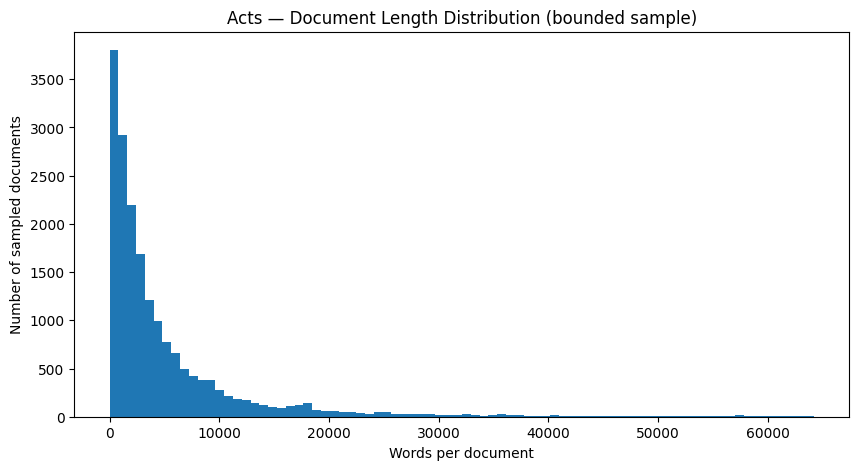

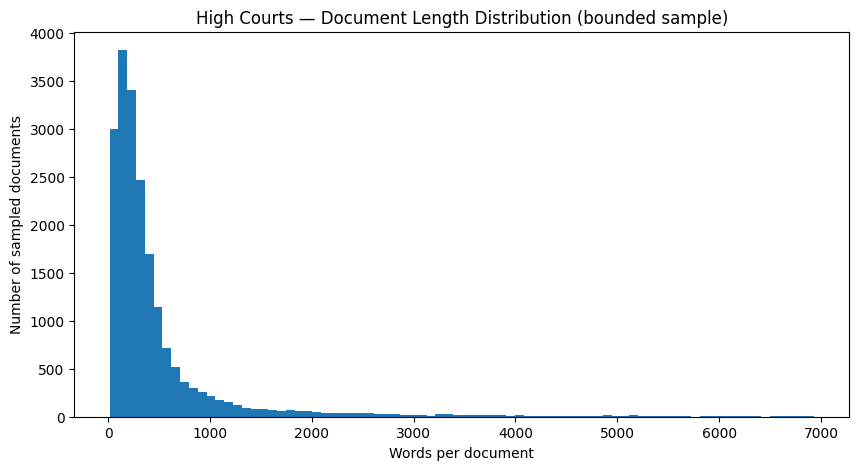

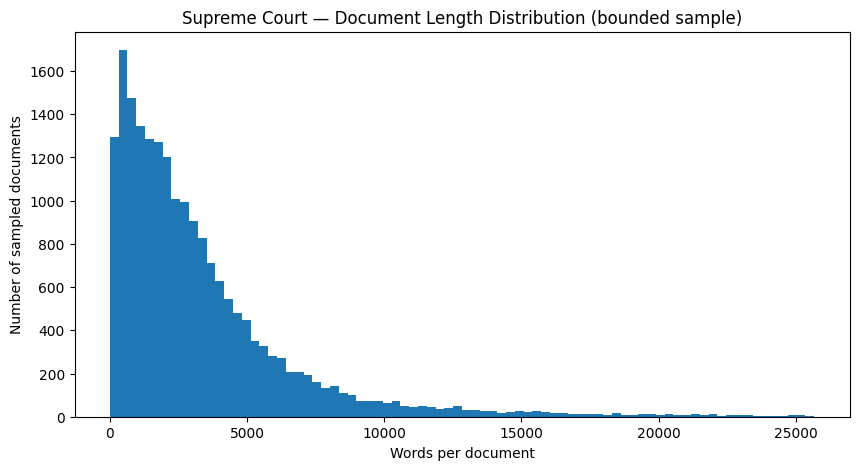

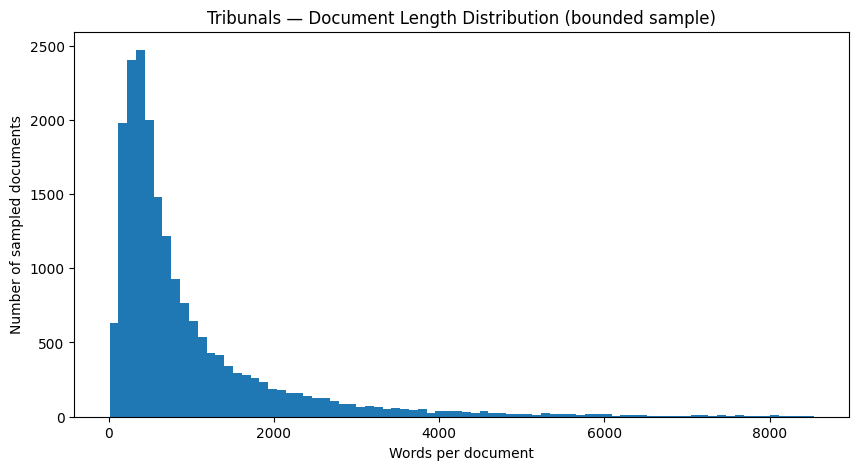

In [24]:
# ============================================================
# CELL 14 — Document length plots
# ============================================================

for source, s in stats.items():

    lengths = np.asarray(s["length_sample"])

    if len(lengths) == 0:
        continue

    p99 = np.percentile(lengths, 99)

    plt.figure(figsize=(10, 5))

    plt.hist(
        lengths[lengths <= p99],
        bins=80
    )

    plt.xlabel("Words per document")
    plt.ylabel("Number of sampled documents")
    plt.title(
        f"{source} — Document Length Distribution "
        "(bounded sample)"
    )

    plt.show()

In [25]:
# ============================================================
# CELL 15 — Random document samples
# ============================================================

for source, s in stats.items():

    print("\n" + "=" * 100)
    print(source.upper())
    print("=" * 100)

    for i, record in enumerate(s["reservoir"], 1):

        print("\n" + "-" * 100)
        print(f"RANDOM SAMPLE {i}")
        print("-" * 100)

        print(text_from_record(record)[:5000])


ACTS

----------------------------------------------------------------------------------------------------
RANDOM SAMPLE 1
----------------------------------------------------------------------------------------------------
The Tirunelveli City Municipal Corporation Act, 1994 Tamil Nadu Act 28 of 1994 Statement of Objects and Reasons - Tirunelveli City Municipal Corporation Act, 1994 (Tamil Nadu Act 28 of 1994). - The question of constituting a municipal corporation for Tirunelveli has been engaging the attention of the Government for some time past. Apart from the numerous requests made on the floor of the Legislative Assembly and representations received from the public, the town has significantly developed industrially and therefore, civic amenities of a high order are the legitimate expectation of the people of the town. In all counts it has reached the status of a corporation and is ripe to be upgraded as such. The Government, therefore, took a decision to upgrade municipality in

In [26]:
# ============================================================
# CELL 16 — Short and long document examples
# ============================================================

# A second bounded streaming pass.
# We retain only a few shortest and longest documents.

shortest = {}
longest = {}

for source, path in file_paths.items():

    short_list = []
    long_list = []

    for record in stream_records(path):

        text = text_from_record(record)

        if not text.strip():
            continue

        words = len(text.split())

        short_list.append((words, text[:3000]))
        short_list.sort(key=lambda x: x[0])
        del short_list[3:]

        long_list.append((words, text[:3000]))
        long_list.sort(key=lambda x: x[0], reverse=True)
        del long_list[3:]

    shortest[source] = short_list
    longest[source] = long_list

for source in file_paths:

    print("\n" + "=" * 80)
    print(source.upper(), "— SHORTEST")
    print("=" * 80)

    for words, text in shortest[source]:
        print(f"\nWords: {words}")
        print(text)

    print("\n" + "=" * 80)
    print(source.upper(), "— LONGEST")
    print("=" * 80)

    for words, text in longest[source]:
        print(f"\nWords: {words}")
        print(text)


ACTS — SHORTEST

Words: 1
![](/indigo/media/Screenshot%20from%202022-10-06%2012-31-22.png)

Words: 10
Finance (No. 2) Act, 2019 (Act No. 23 of 2019)

Words: 16
Chaitanya Godavari Grameena Bank (Employees') Pension Regulations, 2018 Published vide Notification F. No. CGGB/Pension/2018-19, dated 30.10.2018

ACTS — LONGEST

Words: 503777
The Income Tax Act, 1961 (43 of 1961)[13th September, 1961] An Act to consolidate and amend the law relating to income-tax [and super-tax] [The Income-tax Act, 1961 applies to the State of Sikkim with effect from the previous year relevant to the assessment year commencing on the 1st day of April, 1990. See Section 26 of the Finance Act, 1989. The Act has also been extended to the Continental Shelf of India. See Notification No. G. S. R. 304 (E), dated 31.3.1983.]. Be it enacted by Parliament in the Twelfth Year of the Republic of India as follows:-
Chapter I Preliminary

1. Short title, extent and commencement.
(1) This Act may be called The Income-tax 

In [27]:
# ============================================================
# CELL 17 — Whitespace / formatting exploration
# ============================================================

for source, path in file_paths.items():

    newline_count = 0
    tab_count = 0
    multiple_space_count = 0
    docs_seen = 0

    for record in stream_records(path):

        text = text_from_record(record)

        if not text:
            continue

        docs_seen += 1

        newline_count += text.count("\n")
        tab_count += text.count("\t")
        multiple_space_count += len(
            re.findall(r" {2,}", text)
        )

    print("\n" + "=" * 70)
    print(source.upper())
    print("=" * 70)

    print("Documents:", f"{docs_seen:,}")
    print("Newline characters:", f"{newline_count:,}")
    print("Tab characters:", f"{tab_count:,}")
    print(
        "Multiple-space occurrences:",
        f"{multiple_space_count:,}"
    )


ACTS
Documents: 18,822
Newline characters: 4,033,621
Tab characters: 0
Multiple-space occurrences: 0

HIGH COURTS
Documents: 2,536,738
Newline characters: 112,245,621
Tab characters: 0
Multiple-space occurrences: 0

SUPREME COURT
Documents: 55,528
Newline characters: 2,944,852
Tab characters: 0
Multiple-space occurrences: 3,710

TRIBUNALS
Documents: 869,132
Newline characters: 53,590,546
Tab characters: 0
Multiple-space occurrences: 0


In [28]:
# ============================================================
# CELL 18 — Character / Unicode exploration on a bounded sample
# ============================================================

CHAR_SAMPLE_DOCS = 1000

for source, path in file_paths.items():

    char_counter = Counter()
    docs_seen = 0

    for record in stream_records(path):

        text = text_from_record(record)

        if not text:
            continue

        char_counter.update(text)

        docs_seen += 1

        if docs_seen >= CHAR_SAMPLE_DOCS:
            break

    print("\n" + "=" * 80)
    print(source.upper())
    print(f"First {docs_seen:,} non-empty documents")
    print("=" * 80)

    print("Unique characters in sample:", len(char_counter))

    print("\nMost common characters:")

    for char, count in char_counter.most_common(40):
        print(f"{repr(char):15s} {count:,}")


ACTS
First 1,000 non-empty documents
Unique characters in sample: 197

Most common characters:
' '             7,192,500
'e'             4,201,441
't'             3,061,087
'o'             2,689,967
'a'             2,580,073
'i'             2,505,291
'n'             2,431,183
'r'             2,265,331
's'             2,029,930
'h'             1,587,827
'd'             1,270,009
'c'             1,239,505
'l'             1,171,813
'f'             949,552
'u'             901,780
'm'             789,326
'p'             743,651
'.'             685,507
'y'             574,012
'b'             566,407
'g'             435,006
','             399,376
'v'             334,333
'w'             305,788
'\n'            233,124
')'             225,163
'('             224,967
'1'             190,825
'-'             152,365
'C'             137,049
'A'             132,075
'S'             129,350
'2'             111,234
'x'             96,943
'k'             94,717
'0'             93,005
'T'             8

In [29]:
# ============================================================
# CELL 19 — Bounded vocabulary exploration
# ============================================================

# IMPORTANT:
# Do NOT create a Counter over every word in the entire corpus.
# A legal corpus can contain millions of distinct strings.
#
# Instead we intentionally analyze a bounded sample.

VOCAB_COUNTER = Counter()
BIGRAM_COUNTER = Counter()

for source, path in file_paths.items():

    docs_seen = 0
    chars_seen = 0

    for record in stream_records(path):

        text = text_from_record(record)

        if not text.strip():
            continue

        if docs_seen >= VOCAB_SAMPLE_DOCUMENTS:
            break

        if chars_seen >= VOCAB_SAMPLE_CHARS:
            break

        words = re.findall(
            r"\b\w+\b",
            text.lower()
        )

        VOCAB_COUNTER.update(words)

        for i in range(len(words) - 1):
            BIGRAM_COUNTER[
                (words[i], words[i + 1])
            ] += 1

        docs_seen += 1
        chars_seen += len(text)

    print(
        f"{source}: "
        f"{docs_seen:,} documents, "
        f"{chars_seen:,} characters sampled"
    )

print("\nBounded vocabulary exploration complete.")

Acts: 504 documents, 20,611,325 characters sampled
High Courts: 5,000 documents, 13,974,521 characters sampled
Supreme Court: 629 documents, 20,016,481 characters sampled
Tribunals: 778 documents, 20,009,139 characters sampled

Bounded vocabulary exploration complete.


In [30]:
# ============================================================
# CELL 20 — Common words
# ============================================================

print("=" * 70)
print("TOP 100 WORDS IN BOUNDED EXPLORATION SAMPLE")
print("=" * 70)

for word, count in VOCAB_COUNTER.most_common(100):
    print(f"{word:30s} {count:>12,}")

TOP 100 WORDS IN BOUNDED EXPLORATION SAMPLE
the                               1,168,159
of                                  641,084
to                                  325,486
in                                  282,123
and                                 274,101
a                                   167,680
for                                 160,078
be                                  147,635
by                                  145,863
is                                  142,089
that                                135,773
or                                  128,010
as                                  106,499
on                                   99,860
not                                  79,490
it                                   75,940
no                                   74,334
any                                  72,950
this                                 71,348
shall                                70,744
was                                  67,993
has                             

In [31]:
# ============================================================
# CELL 21 — Rare words in bounded sample
# ============================================================

frequencies = np.asarray(
    list(VOCAB_COUNTER.values())
)

print("Unique words in sample:", len(VOCAB_COUNTER))

for threshold in [1, 2, 5, 10, 50, 100]:

    count = np.sum(frequencies <= threshold)

    print(
        f"Words appearing <= {threshold:>3} times: "
        f"{count:,}"
    )

Unique words in sample: 86345
Words appearing <=   1 times: 39,878
Words appearing <=   2 times: 50,970
Words appearing <=   5 times: 62,077
Words appearing <=  10 times: 68,305
Words appearing <=  50 times: 77,702
Words appearing <= 100 times: 80,302


In [32]:
# ============================================================
# CELL 22 — Common legal bigrams
# ============================================================

print("=" * 70)
print("TOP 100 BIGRAMS IN BOUNDED EXPLORATION SAMPLE")
print("=" * 70)

for phrase, count in BIGRAM_COUNTER.most_common(100):

    print(
        f"{' '.join(phrase):45s} "
        f"{count:,}"
    )

TOP 100 BIGRAMS IN BOUNDED EXPLORATION SAMPLE
of the                                        219,795
in the                                        84,956
to the                                        74,218
by the                                        71,877
for the                                       53,289
that the                                      47,504
to be                                         37,362
the state                                     34,324
shall be                                      34,301
on the                                        32,831
the appellant                                 32,721
and the                                       28,664
it is                                         25,788
counsel for                                   24,799
with the                                      23,964
has been                                      21,434
from the                                      20,794
may be                                        18,702

In [33]:
# ============================================================
# CELL 23 — Duplicate analysis without storing the entire corpus
# ============================================================

# Exact duplicate detection can also consume a lot of RAM if we keep
# a Python set containing every document hash.
#
# For the first exploration pass, use a bounded hash sample.

DUPLICATE_SAMPLE_SIZE = 100_000

seen_hashes = set()
duplicate_count = 0
hashed_documents = 0

for source, path in file_paths.items():

    for record in stream_records(path):

        text = text_from_record(record)

        if not text:
            continue

        # Only keep a bounded number of hashes.
        if hashed_documents >= DUPLICATE_SAMPLE_SIZE:
            break

        h = hashlib.sha256(
            text.encode("utf-8")
        ).digest()

        if h in seen_hashes:
            duplicate_count += 1
        else:
            seen_hashes.add(h)

        hashed_documents += 1

    if hashed_documents >= DUPLICATE_SAMPLE_SIZE:
        break

print("Documents checked:", f"{hashed_documents:,}")
print("Duplicate hashes in sample:", f"{duplicate_count:,}")
print(
    "This is a bounded preliminary duplicate check, "
    "not a full-corpus duplicate count."
)

Documents checked: 100,000
Duplicate hashes in sample: 90
This is a bounded preliminary duplicate check, not a full-corpus duplicate count.


## Tokenization experiment

For tokenizer analysis we only use a small number of documents from each
source. Tokenizing the entire legal corpus here is unnecessary and can
consume substantial RAM/CPU.

In [34]:
# ============================================================
# CELL 24 — Load tokenizer
# ============================================================

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "openai-community/gpt2"
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded.")
print("Vocabulary size:", len(tokenizer))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded.
Vocabulary size: 50257


In [35]:
# ============================================================
# CELL 25 — Tokenization sample
# ============================================================

tokenization_rows = []

for source, path in file_paths.items():

    sample_records = []

    # Reservoir sample only TOKENIZATION_SAMPLE_SIZE documents.
    seen = 0

    for record in stream_records(path):

        text = text_from_record(record)

        if not text.strip():
            continue

        seen += 1

        if len(sample_records) < TOKENIZATION_SAMPLE_SIZE:
            sample_records.append(text)
        else:
            j = random.randint(0, seen - 1)

            if j < TOKENIZATION_SAMPLE_SIZE:
                sample_records[j] = text

    print(
        f"{source}: sampled "
        f"{len(sample_records)} documents"
    )

    for text in sample_records:

        words = len(text.split())

        tokens = tokenizer.encode(
            text,
            add_special_tokens=False
        )

        tokenization_rows.append({
            "source": source,
            "words": words,
            "tokens": len(tokens),
            "tokens_per_word": (
                len(tokens) / max(words, 1)
            )
        })

tokenization_df = pd.DataFrame(tokenization_rows)

print("\nTokenization sampling complete.")

Token indices sequence length is longer than the specified maximum sequence length for this model (24161 > 1024). Running this sequence through the model will result in indexing errors


Acts: sampled 50 documents
High Courts: sampled 50 documents
Supreme Court: sampled 50 documents
Tribunals: sampled 50 documents

Tokenization sampling complete.


In [36]:
# ============================================================
# CELL 26 — Tokenization statistics
# ============================================================

display(
    tokenization_df
    .groupby("source")
    [["words", "tokens", "tokens_per_word"]]
    .mean()
)

print("\nOverall:")
display(
    tokenization_df[
        ["words", "tokens", "tokens_per_word"]
    ].mean().to_frame("mean")
)

,words,tokens,tokens_per_word
source,,,
Acts,7784.24,10268.80,1.383833
High Courts,724.36,1053.38,1.657993
Supreme Court,3082.58,3919.22,1.313069
Tribunals,1754.88,2758.58,1.772027



Overall:


,mean
words,3336.51500
tokens,4499.99500
tokens_per_word,1.53173


In [37]:
# ============================================================
# CELL 27 — Context-length coverage
# ============================================================

token_lengths = tokenization_df["tokens"].to_numpy()

print("=" * 70)
print("TOKEN LENGTH DISTRIBUTION")
print("=" * 70)

for p in [25, 50, 75, 90, 95, 99]:

    print(
        f"{p:>2}th percentile: "
        f"{np.percentile(token_lengths, p):,.0f} tokens"
    )

print(
    f"Maximum in sample: {token_lengths.max():,} tokens"
)

print("\nContext coverage:")

for context_length in [512, 1024, 2048, 4096]:

    percentage = (
        np.mean(token_lengths <= context_length) * 100
    )

    print(
        f"{context_length:>4} tokens: "
        f"{percentage:6.2f}% of sampled documents fit entirely"
    )

TOKEN LENGTH DISTRIBUTION
25th percentile: 622 tokens
50th percentile: 1,406 tokens
75th percentile: 3,900 tokens
90th percentile: 11,375 tokens
95th percentile: 19,298 tokens
99th percentile: 46,951 tokens
Maximum in sample: 115,977 tokens

Context coverage:
 512 tokens:  17.50% of sampled documents fit entirely
1024 tokens:  41.50% of sampled documents fit entirely
2048 tokens:  58.50% of sampled documents fit entirely
4096 tokens:  76.00% of sampled documents fit entirely


In [38]:
# ============================================================
# CELL 28 — Final summary
# ============================================================

print("=" * 80)
print("PHASE 1 — LOW-MEMORY DATA EXPLORATION SUMMARY")
print("=" * 80)

print("\nCORPUS")
print("-" * 80)
print(f"Total documents:  {int(total_docs):,}")
print(f"Total words:      {int(total_words):,}")

print("\nPER SOURCE")
print("-" * 80)

for source, s in stats.items():

    lengths = np.asarray(s["length_sample"])

    print(
        f"{source:20s} | "
        f"docs={s['documents']:,} | "
        f"words={s['total_words']:,} | "
        f"median={np.median(lengths):,.0f}"
    )

print("\nTOKENIZATION SAMPLE")
print("-" * 80)
print(
    "Mean tokens/word:",
    f"{tokenization_df['tokens_per_word'].mean():.4f}"
)

print(
    "Median tokens/word:",
    f"{tokenization_df['tokens_per_word'].median():.4f}"
)

print("\nIMPORTANT")
print("-" * 80)
print("All four files were explored without loading the complete")
print("JSON datasets into RAM.")
print("=" * 80)

PHASE 1 — LOW-MEMORY DATA EXPLORATION SUMMARY

CORPUS
--------------------------------------------------------------------------------
Total documents:  3,480,245
Total words:      2,900,680,187

PER SOURCE
--------------------------------------------------------------------------------
Acts                 | docs=18,826 | words=119,638,348 | median=2,624
High Courts          | docs=2,536,738 | words=1,594,919,242 | median=266
Supreme Court        | docs=55,549 | words=210,205,151 | median=2,383
Tribunals            | docs=869,132 | words=975,917,446 | median=580

TOKENIZATION SAMPLE
--------------------------------------------------------------------------------
Mean tokens/word: 1.5317
Median tokens/word: 1.4117

IMPORTANT
--------------------------------------------------------------------------------
All four files were explored without loading the complete
JSON datasets into RAM.


In [41]:
# ============================================================
# CELL — URL exploration by domain and frequency
# ============================================================

import re
from collections import Counter

url_pattern = r'https?://[^\s<>"\')\]]+'

for source, path in file_paths.items():

    url_counter = Counter()
    total_urls = 0
    malformed = []

    for record in stream_records(path):

        text = text_from_record(record)

        matches = re.findall(
            url_pattern,
            text,
            flags=re.IGNORECASE
        )

        for url in matches:

            total_urls += 1
            url_counter[url] += 1

            # Very rough malformed-URL check
            if (
                "http://" == url.lower()
                or "https://" == url.lower()
                or "http:///" in url.lower()
                or len(url) < 10
            ):
                malformed.append(url)

    print("\n" + "=" * 80)
    print(source)
    print("=" * 80)

    print("Total URLs:", f"{total_urls:,}")
    print("Unique URLs:", f"{len(url_counter):,}")
    print("Malformed/suspicious URLs:", f"{len(malformed):,}")

    print("\nTop 30 repeated URLs:")
    for url, count in url_counter.most_common(30):
        print(f"{count:>6}  {url[:250]}")

    print("\nSuspicious examples:")
    for url in malformed[:20]:
        print(" ", url)


Acts
Total URLs: 0
Unique URLs: 0
Malformed/suspicious URLs: 0

Top 30 repeated URLs:

Suspicious examples:

High Courts
Total URLs: 199,330
Unique URLs: 726
Malformed/suspicious URLs: 6

Top 30 repeated URLs:
195705  https://hcservices.ecourts.gov.in/hcservices/
  1138  http://www.judis.nic.in
   562  https://www.mhc.tn.gov.in/judis
   159  https://www.mhc.tn.gov.in/judis/
    88  https://indiankanoon.org
    52  https://indiankanoo
    45  https://indiankanoon.org/doc/694670/
    42  http://itatonlin.org
    42  https://indiankanoon.org/doc/1123043/
    42  https://indiankanoon.org/doc/694670
    37  https://hcservices.ecourts.gov.in/hcservices/.
    31  http://www.ap.gov.in/goir
    31  http://www.apfinance.gov.in.
    16  https://indiankanoon.org/doc/1542085/
    13  http://indiankanoon.org/doc/295920/
    13  https://tripuratenders.gov.in
    12  https://www.irctc.co.in/eticketing/printTicket.jsf?pnr=6346903251^B^05-Dec-2015^0^
    12  https://hcservices.ecourts.gov.in/hcservices

In [42]:
# ============================================================
# CELL — Detect Unicode replacement-character corruption
# ============================================================

REPLACEMENT_CHAR = "\ufffd"

for source, path in file_paths.items():

    corrupted_docs = 0
    total_replacement_chars = 0
    worst_examples = []

    for record in stream_records(path):

        text = text_from_record(record)

        count = text.count(REPLACEMENT_CHAR)

        if count > 0:

            corrupted_docs += 1
            total_replacement_chars += count

            # Keep only the worst examples
            words = len(text.split())

            worst_examples.append(
                (count, words, text[:3000])
            )

            worst_examples.sort(
                key=lambda x: x[0],
                reverse=True
            )

            worst_examples = worst_examples[:5]

    print("\n" + "=" * 80)
    print(source)
    print("=" * 80)

    print(
        "Documents containing �:",
        f"{corrupted_docs:,}"
    )

    print(
        "Total � characters:",
        f"{total_replacement_chars:,}"
    )

    print("\nWorst examples:")

    for count, words, text in worst_examples:

        print("\n" + "-" * 70)
        print("Replacement characters:", count)
        print("Words:", words)
        print("-" * 70)
        print(text)


Acts
Documents containing �: 3
Total � characters: 3

Worst examples:

----------------------------------------------------------------------
Replacement characters: 1
Words: 4147
----------------------------------------------------------------------
In exercise of powers conferred on it by subsection (4) of Section 91 read with Section 181 of the Electricity Act, 2003 (36 of 2003), and all other powers enabling it in that behalf, the Joint Electricity Regulatory Commission for UT of Jammu & Kashmir and UT of Ladakh, after previous publication, hereby makes the following regulations, namely:
1. Short Title and Commencement.
1. 1 These regulations may be called the Joint Electricity Regulatory Commission for UT of Jammu & Kashmir and UT of Ladakh (Appointment of Consultants) Regulations, 2023.1.2 These regulations shall come into force from the date of their publication in the Official Gazette:
2. Definitions.
2. 1 In these regulations unless the context otherwise requires: -a. *"Act"*